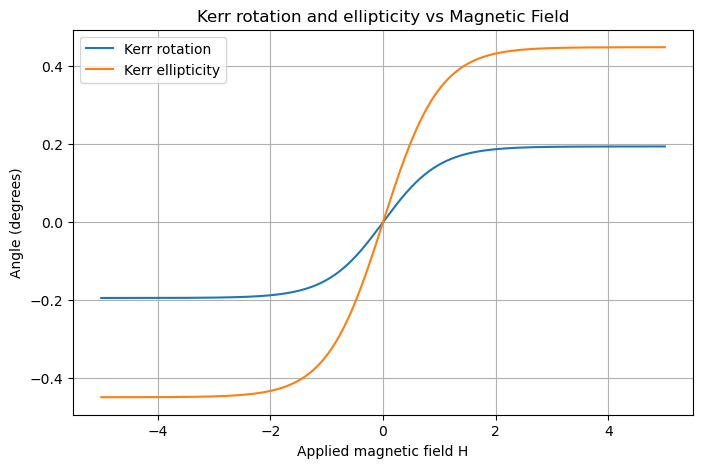

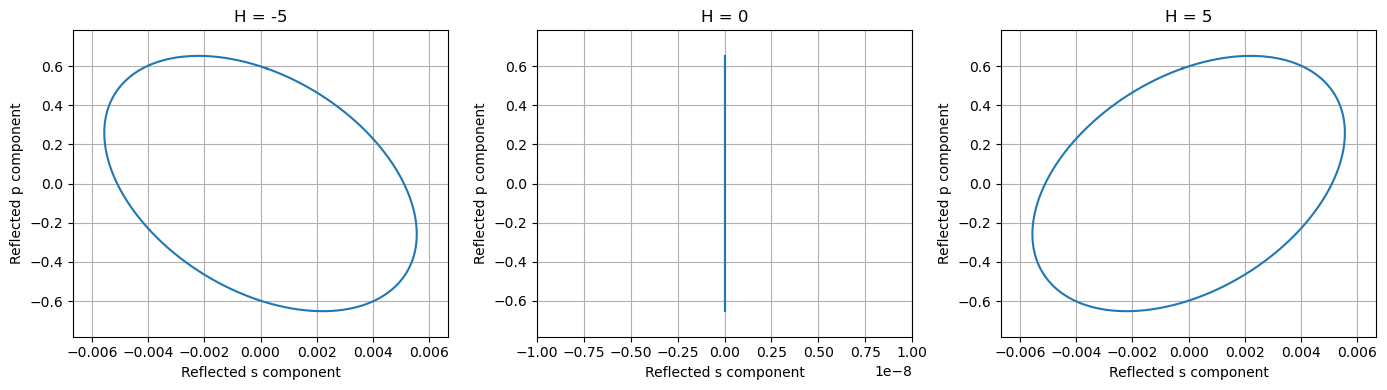

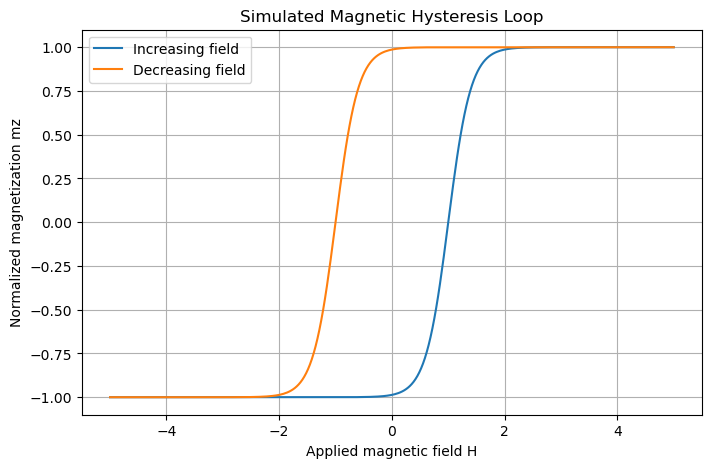

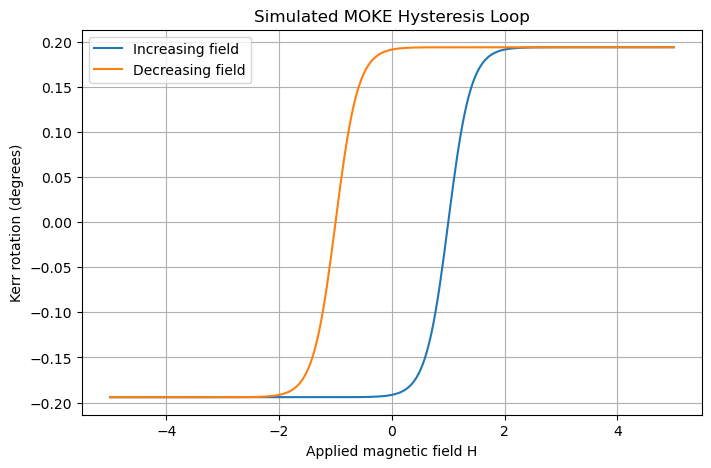

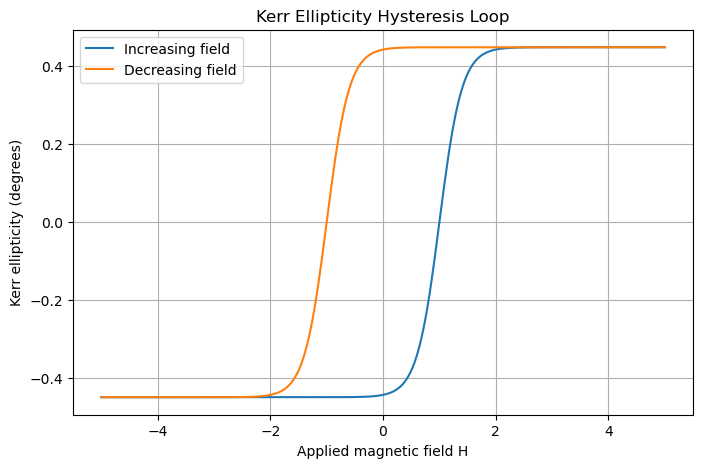

In [36]:
#Part-1(Jathin)
import numpy as np

c = 299792458.0

def compute_derived_constants(lam, theta_i_deg, n_inc=1.0):
  """Computes angular frequency omega, vacuum wavenumber k0, and

  in-plane wavevector component kx.

  Parameters:
  - lam (float): Laser wavelength in meters (e.g., 633e-9 for 633 nm).
  - theta_i_deg (float): Angle of incidence in degrees.
  - n_inc (float): Refractive index of the incident medium (default is 1.0 for
  air).

  Returns:
  - dict: Contains omega, k0, and kx.
  """
  # Speed of light in vacuum (m/s)
  c = 299792458.0

  # Convert angle from degrees to radians
  theta_i = np.radians(theta_i_deg)

  # 1. Angular frequency omega = 2 * pi * c / lambda
  omega = (2.0 * np.pi * c) / lam

  # 2. Vacuum wavenumber k0 = omega / c = 2 * pi / lambda
  k0 = (2.0 * np.pi) / lam

  # 3. In-plane wavevector component kx = k0 * n_inc * sin(theta_i)
  kx = k0 * n_inc * np.sin(theta_i)

  return {"omega": omega, "k0": k0, "kx": kx}

'''values = compute_derived_constants(633e-9, 45, 1)
print(values["omega"],values["k0"],values['kx'])'''

def get_dielectric_tensor(epsilon_d, Q=None, m=None, is_magnetic=False):
  """Builds the 3x3 dielectric tensor for a layer.

  Parameters:
  - epsilon_d (complex or float): Material optical constant (permittivity).
  - Q (complex or float): Voigt magneto-optical parameter.
  - m (tuple or list): Magnetization vector [mx, my, mz].
  - is_magnetic (bool): True for magnetic layers, False for non-magnetic layers.

  Returns:
  - numpy.ndarray: 3x3 complex dielectric tensor.
  """
  if not is_magnetic or Q is None or m is None:
    # For a non-magnetic layer, the tensor is just epsilon_d * I_3x3
    return epsilon_d * np.eye(3, dtype=complex)
  else:
    mx, my, mz = m
    # For a magnetic layer, construct the full tensor
    tensor_matrix = np.array(
        [
            [1.0, 1j * Q * mz, -1j * Q * my],
            [-1j * Q * mz, 1.0, 1j * Q * mx],
            [1j * Q * my, -1j * Q * mx, 1.0],
        ],
        dtype=complex,
    )
    return epsilon_d * tensor_matrix

'''epsilon_d = -11.49 + 18.32j
Q = 0.0283 + 0.0066j
m = (0, 0, 1)
eps = get_dielectric_tensor(epsilon_d, Q, m, is_magnetic=True)
print("Dielectric tensor of Cobalt:")
print(eps)
print("\nOff-diagonal element epsilon_xy:")
print(eps[0, 1])'''

#Part-2(Athul)

def berreman_matrix(eps,kx,k0):    #HERE THE DIELECTRIC TENSOR(eps) IS THE ONE CALCULATED FROM ABOVE

    xi  = kx/k0  #Normalized wavefn

    eps = np.asarray(eps, dtype=complex)

    # Extracting tensor components
    exx, exy, exz = eps[0, 0], eps[0, 1], eps[0, 2]
    eyx, eyy, eyz = eps[1, 0], eps[1, 1], eps[1, 2]
    ezx, ezy, ezz = eps[2, 0], eps[2, 1], eps[2, 2]


    # Construct Delta matrix elements row by row
    row0 = [-xi * ezx / ezz, 1.0 - (xi ** 2) / ezz, -xi * ezy / ezz, 0.0]
    row1 = [exx - exz * ezx / ezz, -xi * exz/ezz, exy - exz * ezy / ezz, 0.0]
    row2 = [0.0, 0.0, 0.0, 1.0]
    row3 = [eyx - eyz * ezx / ezz, -xi * eyz/ezz, eyy - eyz * ezy / ezz - (xi ** 2), 0.0]

    delta = np.array([row0, row1, row2, row3], dtype=complex)

    return delta

delta = berreman_matrix(eps, kx, k0)

'''print("Normalized wavevector xi =", kx/k0)

print("\nBerreman Matrix Delta:")
np.set_printoptions(
    precision=4,
    suppress=True,
    linewidth=120
)
print(delta)'''

#Part-3
import scipy
from scipy.linalg import expm

def Transfer_matrix(k0,d,delta):
    return scipy.linalg.expm(1j * k0 * d * delta)  

'''T = T_total(k0, d, delta)
print("k0*d =", k0*d)
print("Transfer matrix T:")
print(np.round(T, 5))
print("Shape:", T.shape)'''

#Part-4(Rohith)

n_inc = 1.0
n_sub = 1.5
theta_i_deg = 45
lam = 633e-9
d = 20e-9
m = 0,0,1
epsilon_d = -11.49+18.32j
Q = 0.0283+0.0066j

theta_i = np.radians(theta_i_deg)
omega = (2.0 * np.pi * c) / lam
k0 = (2.0 * np.pi) / lam
kx = k0 * n_inc * np.sin(theta_i)

eps = get_dielectric_tensor(epsilon_d, Q, m, is_magnetic=True)
delta = berreman_matrix(eps,kx,k0)

T_total = Transfer_matrix(k0,d,delta)

theta_t = np.arcsin(n_inc * np.sin(theta_i) / n_sub)

cos_i = np.cos(theta_i)
cos_t = np.cos(theta_t)

'''print("Incident angle:", np.degrees(theta_i))
print("Transmission angle:", np.degrees(theta_t))
print("cos(theta_i):", cos_i)
print("cos(theta_t):", cos_t)'''


L_inc = np.array([
    [0, cos_i],
    [0, n_inc],
    [1, 0],
    [n_inc * cos_i, 0]
], dtype=complex)


L_ref = np.array([
    [0, -cos_i],
    [0, n_inc],
    [1, 0],
    [-n_inc * cos_i, 0]
], dtype=complex)


L_trans = np.array([
    [0, cos_t],
    [0, n_sub],
    [1, 0],
    [n_sub * cos_t, 0]
], dtype=complex)

'''print("L_inc:\n", L_inc)
print("L_ref:\n", L_ref)
print("L_trans:\n", L_trans)

print("Shapes:")
print(L_inc.shape, L_ref.shape, L_trans.shape)'''

T_Lref = T_total @ L_ref

A = np.hstack((L_ref, -T_Lref))#

incident_s = np.array([[1], [0]])
b_s = -T_total @ L_inc @ incident_s
x_s = np.linalg.solve(A, b_s)

incident_p = np.array([[0], [1]])
b_p = -T_total @ L_inc @ incident_p
x_p = np.linalg.solve(A, b_p)

r_ss = x_s[0, 0]
r_ps = x_s[1, 0]
r_sp = x_p[0, 0]
r_pp = x_p[1, 0]

R = np.array([
    [r_ss, r_sp],
    [r_ps, r_pp]
])

'''print("Matrix A:")
print(A)
print("\nSolution for incident s-polarization:")
print(x_s)
print("\nSolution for incident p-polarization:")
print(x_p)
print("\nReflection Matrix R:")
print(R)
print("\nBoundary residual for s:")
print(np.linalg.norm(A @ x_s - b_s))
print("\nBoundary residual for p:")
print(np.linalg.norm(A @ x_p - b_p))'''

# part 6 - complex Kerr ratio

rho_K = r_sp / r_pp     # verify sign, depends on polarization of the incident light
theta_K = np.real(rho_K)
eta_K = np.imag(rho_K)

theta_K_deg = np.degrees(theta_K)
eta_K_deg = np.degrees(eta_K)

'''print("Kerr rotation (rad):", theta_K)
print("Kerr ellipticity (rad):", eta_K)
print("Kerr rotation (deg):", theta_K_deg)
print("Kerr ellipticity (deg):", eta_K_deg)'''

import matplotlib.pyplot as plt

'''# Magnetic field range (arbitrary units)
H = np.linspace(-5, 5, 500)

# Characteristic field scale
Hc = 1.0

# Normalized magnetization
mz = np.tanh(H / Hc)

H_values = [-5, -1, 0, 1, 5]
Hc = 1.0

for H_value in H_values:
    mz_value = np.tanh(H_value / Hc)
    m = (0, 0, mz_value)

    eps = get_dielectric_tensor(
        epsilon_d, Q, m, is_magnetic=True
    )

    print(f"\nH = {H_value}")
    print(f"mz = {mz_value:.4f}")
    print(f"epsilon_xy = {eps[0,1]}")'''

def calculate_kerr(H_value):

    # 1. Magnetization
    mz_value = np.tanh(H_value / Hc)
    m = (0, 0, mz_value)

    # 2. Dielectric tensor
    eps = get_dielectric_tensor(
        epsilon_d, Q, m, is_magnetic=True
    )

    # 3. Berreman matrix
    delta = berreman_matrix(eps, kx, k0)

    # 4. Transfer matrix
    T = expm(1j * k0 * d * delta)

    # 5. Boundary-condition matrix
    A = np.hstack((T @ L_ref, -L_trans))

    # 6. p-polarized incident light
    incident_p = np.array([[0], [1]])

    b_p = -T @ L_inc @ incident_p

    x_p = np.linalg.solve(A, b_p)

    # 7. Reflection coefficients
    r_sp = x_p[0, 0]
    r_pp = x_p[1, 0]

    # 8. Complex Kerr ratio
    rho = r_sp / r_pp

    a = np.real(rho)
    b = np.imag(rho)

    # 9. Kerr rotation and ellipticity
    theta_K = 0.5 * np.arctan2(
        2*a, 1 - a**2 - b**2
    )

    eta_K = 0.5 * np.arcsin(
        2*b / (1 + a**2 + b**2)
    )

    return np.degrees(theta_K), np.degrees(eta_K)

H_values = np.linspace(-5, 5, 500)

kerr_rotation = []
kerr_ellipticity = []

for H_value in H_values:

    theta_K, eta_K = calculate_kerr(H_value)

    kerr_rotation.append(theta_K)
    kerr_ellipticity.append(eta_K)

kerr_rotation = np.array(kerr_rotation)
kerr_ellipticity = np.array(kerr_ellipticity)

plt.figure(figsize=(8, 5))

plt.plot(H_values, kerr_rotation,
         label="Kerr rotation")

plt.plot(H_values, kerr_ellipticity,
         label="Kerr ellipticity")

plt.xlabel("Applied magnetic field H")
plt.ylabel("Angle (degrees)")
plt.title("Kerr rotation and ellipticity vs Magnetic Field")

plt.legend()
plt.grid(True)
plt.show()

def get_reflected_field(H_value):

    # Magnetization
    mz_value = np.tanh(H_value / Hc)
    m = (0, 0, mz_value)

    # Dielectric tensor
    eps = get_dielectric_tensor(
        epsilon_d, Q, m, is_magnetic=True
    )

    # Berreman matrix
    delta = berreman_matrix(eps, kx, k0)

    # Transfer matrix
    T = expm(1j * k0 * d * delta)

    # Boundary conditions
    A = np.hstack((T @ L_ref, -L_trans))

    incident_p = np.array([[0], [1]])
    b_p = -T @ L_inc @ incident_p

    x_p = np.linalg.solve(A, b_p)

    # Reflected components
    r_sp = x_p[0, 0]
    r_pp = x_p[1, 0]

    return r_sp, r_pp

H_test = [-5, 0, 5]

t = np.linspace(0, 2*np.pi, 1000)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, H_value in zip(axes, H_test):

    r_sp, r_pp = get_reflected_field(H_value)

    E_s = np.real(r_sp * np.exp(1j*t))
    E_p = np.real(r_pp * np.exp(1j*t))

    ax.plot(E_s, E_p)

    ax.set_title(f"H = {H_value}")
    ax.set_xlabel("Reflected s component")
    ax.set_ylabel("Reflected p component")

    # Give the horizontal axis its own scale
    x_max = max(np.max(np.abs(E_s)) * 1.2, 1e-8)
    y_max = np.max(np.abs(E_p)) * 1.2

    ax.set_xlim(-x_max, x_max)
    ax.set_ylim(-y_max, y_max)

    ax.grid(True)

plt.tight_layout()
plt.show()

# Hysteresis parameters
Hc_coercive = 1.0
width = 0.4

# Increasing field: -5 to +5
H_up = np.linspace(-5, 5, 300)

# Decreasing field: +5 to -5
H_down = np.linspace(5, -5, 300)

# Magnetization branches
mz_up = np.tanh((H_up - Hc_coercive) / width)

mz_down = np.tanh((H_down + Hc_coercive) / width)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(H_up, mz_up, label="Increasing field")
plt.plot(H_down, mz_down, label="Decreasing field")

plt.xlabel("Applied magnetic field H")
plt.ylabel("Normalized magnetization mz")
plt.title("Simulated Magnetic Hysteresis Loop")

plt.legend()
plt.grid(True)
plt.show()

def calculate_kerr_from_mz(mz_value):

    # 1. Magnetization vector
    m = (0, 0, mz_value)

    # 2. Dielectric tensor
    eps = get_dielectric_tensor(
        epsilon_d, Q, m, is_magnetic=True
    )

    # 3. Berreman matrix
    delta = berreman_matrix(eps, kx, k0)

    # 4. Transfer matrix
    T = expm(1j * k0 * d * delta)

    # 5. Boundary conditions
    A = np.hstack((T @ L_ref, -L_trans))

    # 6. p-polarized incident light
    incident_p = np.array([[0], [1]])
    b_p = -T @ L_inc @ incident_p

    x_p = np.linalg.solve(A, b_p)

    # 7. Reflection coefficients
    r_sp = x_p[0, 0]
    r_pp = x_p[1, 0]

    # 8. Complex Kerr ratio
    rho = r_sp / r_pp

    a = np.real(rho)
    b = np.imag(rho)

    # 9. Kerr rotation and ellipticity
    theta_K = 0.5 * np.arctan2(
        2*a, 1 - a**2 - b**2
    )

    eta_K = 0.5 * np.arcsin(
        2*b / (1 + a**2 + b**2)
    )

    return np.degrees(theta_K), np.degrees(eta_K)

# Increasing-field branch
kerr_up = []
ellipticity_up = []

for mz_value in mz_up:

    theta, eta = calculate_kerr_from_mz(mz_value)

    kerr_up.append(theta)
    ellipticity_up.append(eta)


# Decreasing-field branch
kerr_down = []
ellipticity_down = []

for mz_value in mz_down:

    theta, eta = calculate_kerr_from_mz(mz_value)

    kerr_down.append(theta)
    ellipticity_down.append(eta)


# Convert to NumPy arrays
kerr_up = np.array(kerr_up)
kerr_down = np.array(kerr_down)

ellipticity_up = np.array(ellipticity_up)
ellipticity_down = np.array(ellipticity_down)

plt.figure(figsize=(8, 5))

plt.plot(H_up, kerr_up, label="Increasing field")
plt.plot(H_down, kerr_down, label="Decreasing field")

plt.xlabel("Applied magnetic field H")
plt.ylabel("Kerr rotation (degrees)")
plt.title("Simulated MOKE Hysteresis Loop")

plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(H_up, ellipticity_up, label="Increasing field")
plt.plot(H_down, ellipticity_down, label="Decreasing field")

plt.xlabel("Applied magnetic field H")
plt.ylabel("Kerr ellipticity (degrees)")
plt.title("Kerr Ellipticity Hysteresis Loop")

plt.legend()
plt.grid(True)
plt.show()